# Spectrogram Encoding:
* Try assigning colors per filename
* For now: Spend time (few hours) playing with powerlaw
* 
* 2 layer (1 hidden layer) NN
* Look at dcase papers and look for 1 step NN, what architectures, model arcitectures (if you have time) 

In [137]:
# imports
import pandas as pd
import numpy as np
import librosa
from pathlib import Path
from scipy.fft import rfft
import umap 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import powerlaw
from scipy.stats import entropy

In [138]:
df_PFS = pd.read_excel("descriptions.xlsx")
df_PFS.head()

,Fish sound,Filename,Begin time,End time,Low frequency (Hz),High frequency (Hz),Duration 90% (s),Centre frequency (Hz),Max power (dB) relative!,notes,category,extra notes,Unnamed: 12,Unnamed: 13
0,6.0,671633444.190702140024.wav,49.658,51.602,49.1,109.8,1.6,70.3,34.0,NaN,a,NaN,NaN,"show a spectrogram for a,b and c fish sounds"
1,9.0,1208221730.181207000246.wav,47.422,49.484,32.7,453.2,1.7,187.5,35.4,good,a,NaN,NaN,NaN
2,10.0,1208221730.181207000246.wav,66.964,67.798,14.0,355.1,0.6,46.9,43.5,NaN,a,NaN,NaN,NaN
3,11.0,1208221730.181207000246.wav,73.105,75.897,37.4,383.1,2.2,152.3,33.9,good,a,NaN,NaN,NaN
4,12.0,1208221730.181207002246.wav,8.168,9.749,39.6,287.4,1.2,128.9,35.6,good,a,NaN,NaN,NaN


In [120]:
def load_and_resample(path, target_sr=2048):
    y, sr = librosa.load(path, sr=2048)
    #y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
    return y, target_sr
    
def frame_audio(y, frame_size=1024, hop_size=1024):
    frames = librosa.util.frame(y, frame_length=frame_size, hop_length=hop_size).T
    return frames
    
def frame_timestamps(num_frames, sr=2048, hop_size=1024):
    return np.arange(num_frames) * (hop_size / sr)

def spectrogram_encode(y, sr, n_fft=1024, hop_length=None, win_length=None):
    # Compute complex STFT
    S = librosa.stft(
        y,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=win_length,
        window='hann',
        center=True,
        pad_mode='constant'
    )

    # Convert to magnitude
    S_mag = np.abs(S)

    # Return frames × freq_bins (transpose)
    return S_mag.T


def label_frames_from_df(timestamps, df, filename):
    # Filter rows for this file only
    df_file = df[df["Filename"] == filename]

    labels = []
    for t in timestamps:
        # Check if t falls inside ANY interval for this file
        is_call = np.any((df_file["Begin time"].values <= t) &
                         (df_file["End time"].values >= t))
        labels.append(1 if is_call else 0)

    return np.array(labels)

def category_frames_from_df(timestamps, df, filename):
    df_file = df[df["Filename"] == filename]

    labels = []
    for t in timestamps:
        # Find all intervals that contain this timestamp
        mask = (df_file["Begin time"].values <= t) & (df_file["End time"].values >= t)

        if np.any(mask):
            # Extract the category for the matching interval
            category = df_file["category"].values[mask][0]
            labels.append(category)
        else:
            labels.append(0)

    return np.array(labels)



def process_multiple_files_df(df = df_PFS, sr=2048, option = 1):
    all_features = []
    all_labels = []
    all_file_ids = []

    # unique filenames from the dataframe
    file_paths = df_PFS[df["Filename"].notna()]["Filename"].unique()

    for fname in file_paths:
        path = Path(fname)  # same directory, so just the name

        # Step 1: load + resample
        y, _ = load_and_resample(str(path), target_sr=sr)

        # Step 2: frame
        # frames = frame_audio(y)
        # timestamps = frame_timestamps(len(frames), sr=sr)
        X = spectrogram_encode(y, sr)
        timestamps = frame_timestamps(X.shape[0], sr=sr)

        # Step 4: label using DataFrame (match on filename only)
        if option == 1: 
            y_labels = label_frames_from_df(timestamps, df, fname) 
        else: 
            y_labels = category_frames_from_df(timestamps, df, fname)

        all_features.append(X)
        all_labels.append(y_labels)
        all_file_ids.extend([fname] * len(y_labels))

    X_all = np.vstack(all_features)
    y_all = np.concatenate(all_labels)

    return X_all, y_all, all_file_ids



In [121]:
# This is the cell to run to get your embeddings and labels
# use option = 1 for 0-1 labels, for the categories use option = 0
X, y, file_ids = process_multiple_files_df(option = 1)

In [122]:
print(X.shape)
print(y.shape)
np.unique(y)

(28779, 513)
(28779,)


array([0, 1])

In [123]:
mask = (y == "a") | (y == "b")
X_ab= X[mask]
y_ab = y[mask]

In [124]:
mask2 = np.isin(y, ["a", "b", "c", "d", "e"])
X_filtered = X[mask2]
y_filtered = y[mask2]

C:\Users\Felic\miniconda3\envs\fish-audio\lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


(28779, 2)


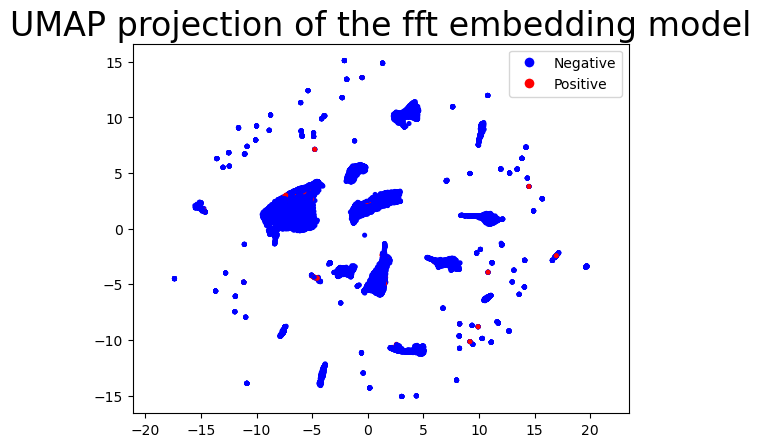

In [126]:
colors = np.where(y == 0, "blue", "red")

reducer = umap.UMAP()

embedding = reducer.fit_transform(X)
print(embedding.shape)


plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    s = 7,
    c = colors)
plt.legend(
    handles=[
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=8)
    ],
    labels=['Negative', 'Positive']
)
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of the fft embedding model', fontsize=24);

(124, 2)


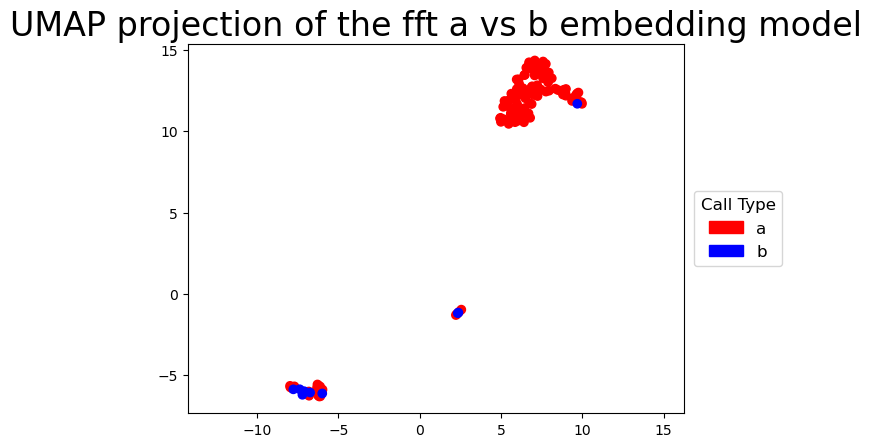

In [115]:
color_map = {
    "a": "red",
    "b": "blue",
    "c": "green",
    "d": "purple",
    "e": "orange",
    0: "gray"   # background/no-call
}

colors = np.array([color_map[label] for label in y_ab])

reducer = umap.UMAP()

embedding = reducer.fit_transform(X_ab)
print(embedding.shape)


plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c = colors)
handles = [
    mpatches.Patch(color=color_map[label], label=label)
    for label in ["a", "b"]
]
plt.legend(handles=handles, title="Call Type", fontsize=12, title_fontsize=12, loc="center left",
    bbox_to_anchor=(1.02, 0.5),   # push legend outside
    borderaxespad=0
)
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of the fft a vs b embedding model', fontsize=24);

(230, 2)


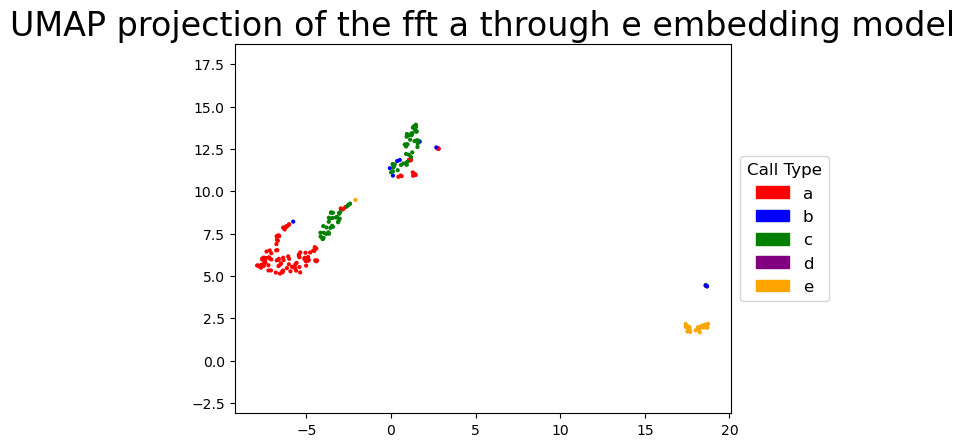

In [118]:
colors = np.array([color_map[label] for label in y_filtered])

reducer = umap.UMAP()

embedding = reducer.fit_transform(X_filtered)
print(embedding.shape)


plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    s = 4,
    c = colors)
handles = [
    mpatches.Patch(color=color_map[label], label=label)
    for label in ["a", "b", "c", "d", "e"]
]
plt.legend(handles=handles, title="Call Type", fontsize=12, title_fontsize=12, loc="center left",
    bbox_to_anchor=(1.02, 0.5),   # push legend outside
    borderaxespad=0
)


plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of the fft a through e embedding model', fontsize=24);

# Power Law Implementation

In [133]:
frame_energy = X.sum(axis=1)

fit = powerlaw.Fit(frame_energy)
print(fit.power_law.alpha)
print(fit.power_law.xmin)

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████████████████████████████████████████████████████████| 28692/28692 [23:06<00:00, 20.70it/s]

1.5680706594432796
12.898127555847168


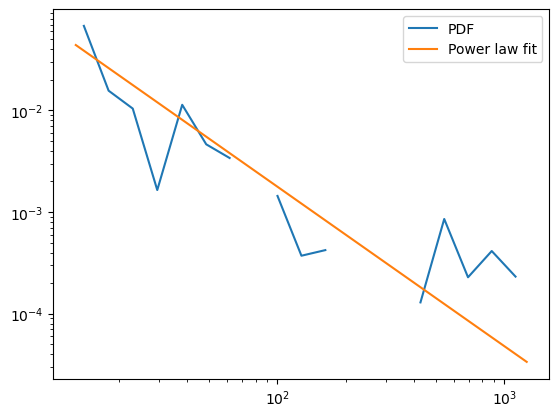

In [135]:
fig, ax = plt.subplots()

fit.plot_pdf(ax=ax, label='PDF')
fit.power_law.plot_pdf(ax=ax, label='Power law fit')

plt.legend()
plt.show()

In [ ]:
# Using entropy 

frame_entropy = entropy(X + 1e-12, axis=1)
fit = powerlaw.Fit(frame_entropy)